# Assignment A1 — CNN vs Transformer trên CIFAR-100 (phần ViT-Small)
**Môn:** Học sâu và ứng dụng trong thị giác máy tính (CO5085)

Notebook này thực hiện **4 thí nghiệm ViT-Small** trên **cùng một split** (theo mục 2.3.3 của report và mục 4 của đề):

| # | Thí nghiệm | Khởi tạo | Phần được huấn luyện |
|---|-----------|----------|----------------------|
| 1 | ViT-S From-Scratch | ngẫu nhiên | toàn bộ |
| 2 | Pretrained – Freeze toàn bộ backbone | ImageNet | chỉ `head` |
| 3 | Pretrained – Partial freeze | ImageNet | 6 block cuối + norm + head |
| 4 | Pretrained – Full fine-tune | ImageNet | toàn bộ |

## 1. Cài đặt thư viện & import

In [1]:
import os, time, json, random, math, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as T
from torchvision.datasets import CIFAR100
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from IPython.display import display

pd.set_option("display.max_rows", 200)       # in được đủ 100 lớp
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

## 2. Cấu hình thí nghiệm

In [ ]:
SEED         = 42
IMG_SIZE     = 32        # độ phân giải đưa vào ViT (32 = giữ nguyên ảnh CIFAR-100)
PATCH_SIZE   = 4         # 32/4 = 8 -> 8x8 = 64 patch
BATCH_SIZE   = 128       # giống report ResNet
EPOCHS       = 20
WEIGHT_DECAY = 1e-3      # AdamW(weight_decay=1e-3) giống report ResNet
NUM_WORKERS  = 2
PARTIAL_FREEZE_BLOCKS = 6  # partial freeze: đóng băng 6/12 block đầu
OUT_DIR      = "/content/a1_outputs"
DATA_DIR     = "/content/data"

# ViT-Small (embed 384, depth 12, heads 6). Trọng số pretrained: ImageNet-21k -> fine-tune ImageNet-1k.
ARCH = "vit_small_patch16_224.augreg_in21k_ft_in1k"

# 4 thí nghiệm. 'freeze': none = train hết | all = chỉ train head | partial = đóng băng nửa đầu
EXPERIMENTS = {
    "scratch":            dict(title="ViT-S From-Scratch",           pretrained=False, freeze="none",    lr=3e-4, drop_path=0.1),
    "pre_freeze_all":     dict(title="Pretrained - Freeze Backbone", pretrained=True,  freeze="all",     lr=1e-3, drop_path=0.0),
    "pre_freeze_partial": dict(title="Pretrained - Partial Freeze",  pretrained=True,  freeze="partial", lr=2e-4, drop_path=0.0),
    "pre_full_ft":        dict(title="Pretrained - Full Fine-tune",  pretrained=True,  freeze="none",    lr=1e-4, drop_path=0.0),
}
ORDER = list(EXPERIMENTS.keys())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(OUT_DIR, exist_ok=True)
torch.backends.cudnn.benchmark = True

def set_seed(seed=SEED):
    """Cố định seed để kết quả tái lập được."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (rất chậm, hãy bật GPU!)")
display(pd.DataFrame(EXPERIMENTS).T)

Device: cuda | Tesla T4


,title,pretrained,freeze,lr,drop_path
scratch,ViT-S From-Scratch,False,none,0.0003,0.1
pre_freeze_all,Pretrained - Freeze Backbone,True,all,0.001,0.0
pre_freeze_partial,Pretrained - Partial Freeze,True,partial,0.0002,0.0
pre_full_ft,Pretrained - Full Fine-tune,True,none,0.0001,0.0


## 3. Dataset & EDA (CIFAR-100)

In [4]:
# ============ TÌM DATASET TRÊN GOOGLE DRIVE (nếu có) ============
# Cách dùng: upload thư mục "cifar-100-python" (hoặc file "cifar-100-python.tar.gz") vào Drive, vào bất kỳ chỗ nào trong DRIVE_SEARCH_DIR.
# Cell này tự tìm, chép sang đĩa local /content/data (đọc nhanh hơn nhiều so với đọc trực tiếp từ Drive khi train).
import shutil, tarfile
from google.colab import drive
drive.mount("/content/drive")

DRIVE_SEARCH_DIR = "/content/drive/MyDrive"      # thu hẹp lại (vd /content/drive/MyDrive/datasets) cho tìm nhanh hơn
DRIVE_BACKUP_DIR = "/content/drive/MyDrive/datasets"   # nơi backup nếu phải tải từ internet
target = os.path.join(DATA_DIR, "cifar-100-python")     # torchvision yêu cầu đúng tên thư mục này
os.makedirs(DATA_DIR, exist_ok=True)

def find_cifar100(root):
    """Duyệt root, trả về (loại, đường dẫn): thư mục chứa train/test/meta hoặc file .tar.gz."""
    for dp, dn, fn in os.walk(root):
        if {"train", "test", "meta"} <= set(fn):                  # thư mục giải nén sẵn (kể cả khi bị đổi tên)
            return "dir", dp
        if "cifar-100-python.tar.gz" in fn:
            return "tar", os.path.join(dp, "cifar-100-python.tar.gz")
    return None, None

if os.path.exists(os.path.join(target, "train")):
    print("Đã có dataset ở local:", target)
else:
    kind, path = find_cifar100(DRIVE_SEARCH_DIR)
    if kind == "dir":
        print("Tìm thấy thư mục trên Drive:", path, "-> chép sang local ...")
        shutil.copytree(path, target)
    elif kind == "tar":
        print("Tìm thấy file nén trên Drive:", path, "-> giải nén sang local ...")
        with tarfile.open(path) as tf: tf.extractall(DATA_DIR)
    else:
        print("Không thấy trên Drive -> tải từ internet rồi backup lên Drive cho lần sau ...")
        CIFAR100(root=DATA_DIR, train=True, download=True)
        os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)
        shutil.copytree(target, os.path.join(DRIVE_BACKUP_DIR, "cifar-100-python"), dirs_exist_ok=True)
        print("Đã backup vào:", DRIVE_BACKUP_DIR)
print("Nội dung", target, "->", sorted(os.listdir(target)))

Mounted at /content/drive
Tìm thấy file nén trên Drive: /content/drive/MyDrive/cifar-100-python.tar.gz -> giải nén sang local ...


/tmp/ipykernel_737/4228917809.py:31: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(path) as tf: tf.extractall(DATA_DIR)


Nội dung /content/data/cifar-100-python -> ['file.txt~', 'meta', 'test', 'train']


In [5]:
# Tải bộ CIFAR-100 gốc (50k train / 10k test). Chưa gắn transform để làm EDA trên ảnh thô.
raw_train = CIFAR100(root=DATA_DIR, train=True,  download=True)
raw_test  = CIFAR100(root=DATA_DIR, train=False, download=True)
CLASS_NAMES = raw_train.classes
NUM_CLASSES = len(CLASS_NAMES)

print("Train :", raw_train.data.shape, raw_train.data.dtype)   # (50000, 32, 32, 3) uint8
print("Test  :", raw_test.data.shape)
print("Số lớp:", NUM_CLASSES)
print("Ví dụ tên lớp:", CLASS_NAMES[:10], "...")

# Kiểm tra cân bằng lớp
train_counts = np.bincount(raw_train.targets, minlength=NUM_CLASSES)
test_counts  = np.bincount(raw_test.targets,  minlength=NUM_CLASSES)
print(f"Ảnh/lớp (train): min={train_counts.min()} max={train_counts.max()} | (test): min={test_counts.min()} max={test_counts.max()}")

# Thống kê mean/std thật của tập train -> đối chiếu với hằng số trong report mục 2.2
arr = raw_train.data / 255.0
print("Mean thật :", arr.mean(axis=(0, 1, 2)).round(4), " | report: [0.5071, 0.4867, 0.4408]")
print("Std  thật :", arr.std(axis=(0, 1, 2)).round(4),  " | report: [0.2675, 0.2565, 0.2761]")
del arr

Train : (50000, 32, 32, 3) uint8
Test  : (10000, 32, 32, 3)
Số lớp: 100
Ví dụ tên lớp: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle'] ...
Ảnh/lớp (train): min=500 max=500 | (test): min=100 max=100
Mean thật : [0.5071 0.4865 0.4409]  | report: [0.5071, 0.4867, 0.4408]
Std  thật : [0.2673 0.2564 0.2762]  | report: [0.2675, 0.2565, 0.2761]


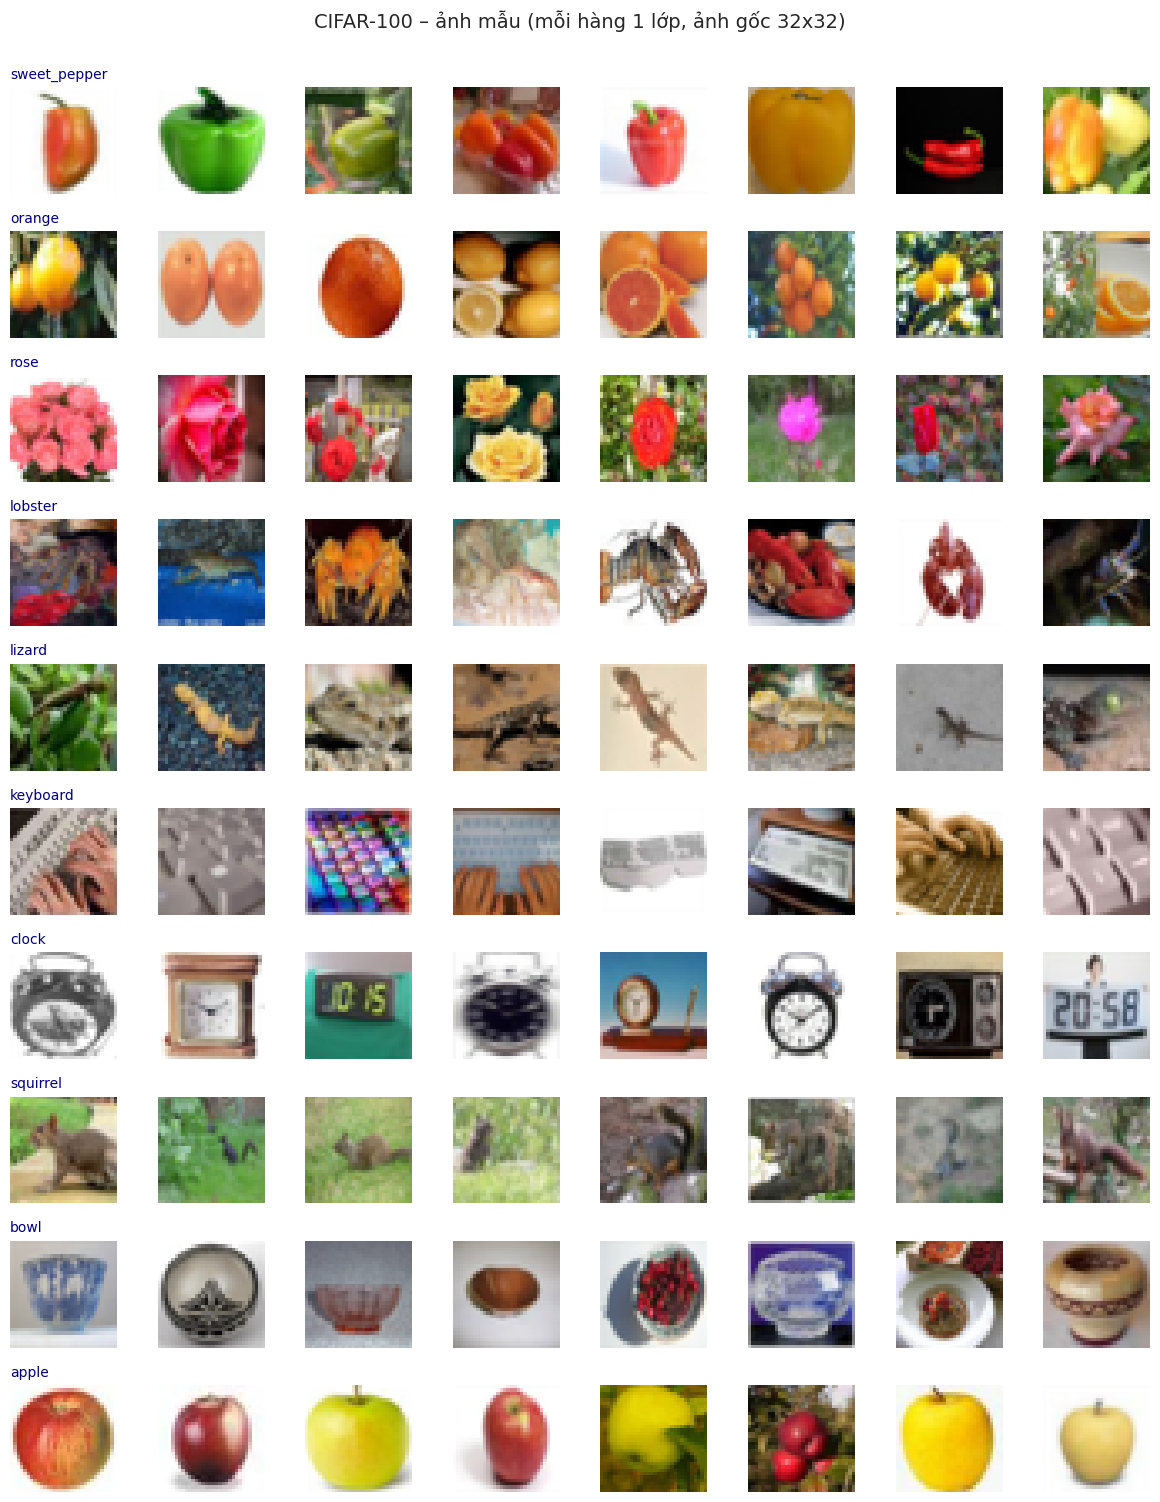

In [6]:
# Lưới ảnh mẫu: 10 lớp ngẫu nhiên x 8 ảnh/lớp
rng = np.random.RandomState(SEED)
show_classes = rng.choice(NUM_CLASSES, 10, replace=False)
targets_np = np.array(raw_train.targets)

fig, axes = plt.subplots(10, 8, figsize=(12, 15))
for r, c in enumerate(show_classes):
    ids = rng.choice(np.where(targets_np == c)[0], 8, replace=False)
    for k, i in enumerate(ids):
        axes[r, k].imshow(raw_train.data[i]); axes[r, k].axis("off")
    axes[r, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=10, color="navy")
plt.suptitle("CIFAR-100 – ảnh mẫu (mỗi hàng 1 lớp, ảnh gốc 32x32)", y=1.0, fontsize=14)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/eda_samples.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Chia dữ liệu

,Subset,Số ảnh,Ảnh/lớp (min-max),Mục đích
0,Training,40000,400-400,Huấn luyện
1,Validation,10000,100-100,Chọn checkpoint tốt nhất / theo dõi overfit
2,Testing,10000,100-100,Đánh giá cuối (không đụng khi train)


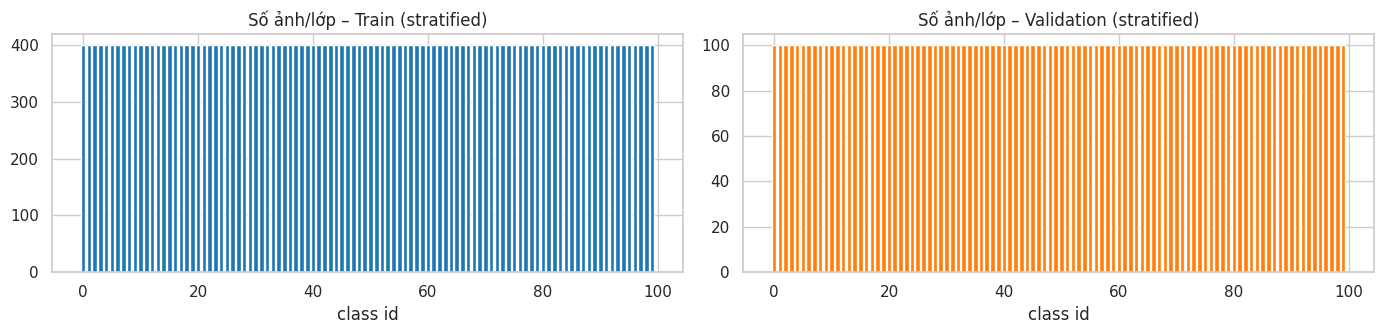

In [7]:
all_idx = np.arange(len(raw_train))
train_idx, val_idx = train_test_split(
    all_idx, test_size=0.2, stratify=targets_np, random_state=SEED)   # stratified: giữ tỉ lệ lớp

assert len(set(train_idx) & set(val_idx)) == 0, "Train/Val bị trùng ảnh!"
tr_cnt = np.bincount(targets_np[train_idx], minlength=NUM_CLASSES)
va_cnt = np.bincount(targets_np[val_idx],   minlength=NUM_CLASSES)

split_df = pd.DataFrame({
    "Subset": ["Training", "Validation", "Testing"],
    "Số ảnh": [len(train_idx), len(val_idx), len(raw_test)],
    "Ảnh/lớp (min-max)": [f"{tr_cnt.min()}-{tr_cnt.max()}", f"{va_cnt.min()}-{va_cnt.max()}", f"{test_counts.min()}-{test_counts.max()}"],
    "Mục đích": ["Huấn luyện", "Chọn checkpoint tốt nhất / theo dõi overfit", "Đánh giá cuối (không đụng khi train)"],
})
display(split_df)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].bar(range(NUM_CLASSES), tr_cnt, color="tab:blue"); ax[0].set_title("Số ảnh/lớp – Train (stratified)"); ax[0].set_xlabel("class id")
ax[1].bar(range(NUM_CLASSES), va_cnt, color="tab:orange"); ax[1].set_title("Số ảnh/lớp – Validation (stratified)"); ax[1].set_xlabel("class id")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/eda_split.png", dpi=150); plt.show()

## 5. Data augmentation + DataLoader

In [8]:
MEAN = (0.5071, 0.4867, 0.4408)    # mean từng kênh RGB của CIFAR-100 (report mục 2.2)
STD  = (0.2675, 0.2565, 0.2761)

resize = [T.Resize(IMG_SIZE, interpolation=T.InterpolationMode.BICUBIC)] if IMG_SIZE != 32 else []

# TRAIN: Raw -> RandomCrop -> (Resize) -> ToTensor -> Normalize
train_tf = T.Compose([
    T.RandomCrop(32, padding=4, padding_mode="reflect"),   # pad 4px kiểu phản xạ -> 40x40 rồi cắt ngẫu nhiên 32x32
    *resize,
    T.ToTensor(),                                          # PIL [0,255] -> tensor [0,1], shape (3,H,W)
    T.Normalize(MEAN, STD),                                # (x - mean) / std
])
# VAL/TEST: Raw -> (Resize) -> ToTensor -> Normalize  (KHÔNG augmentation)
eval_tf = T.Compose([*resize, T.ToTensor(), T.Normalize(MEAN, STD)])

# Hai bản dataset trỏ cùng dữ liệu nhưng khác transform; Subset chọn chỉ số theo split.
ds_train_aug  = CIFAR100(DATA_DIR, train=True,  transform=train_tf)
ds_train_eval = CIFAR100(DATA_DIR, train=True,  transform=eval_tf)
test_set  = CIFAR100(DATA_DIR, train=False, transform=eval_tf)
train_set = Subset(ds_train_aug,  train_idx)   # train: có augmentation
val_set   = Subset(ds_train_eval, val_idx)     # val  : không augmentation

g = torch.Generator(); g.manual_seed(SEED)     # seed cho việc shuffle
loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=g, **loader_kw)
val_loader   = DataLoader(val_set,   batch_size=256, shuffle=False, **loader_kw)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False, **loader_kw)

print(f"Số batch  train/val/test: {len(train_loader)} / {len(val_loader)} / {len(test_loader)}")
xb, yb = next(iter(train_loader))
print("Batch train  x:", tuple(xb.shape), xb.dtype, "| y:", tuple(yb.shape), yb.dtype)
print("Giá trị x   : min=%.3f max=%.3f" % (xb.min(), xb.max()))
print("Mean/Std theo kênh của batch (kỳ vọng ≈ 0 / ≈ 1):", xb.mean((0, 2, 3)).numpy().round(3), xb.std((0, 2, 3)).numpy().round(3))

Số batch  train/val/test: 312 / 40 / 40
Batch train  x: (128, 3, 32, 32) torch.float32 | y: (128,) torch.int64
Giá trị x   : min=-1.897 max=2.025
Mean/Std theo kênh của batch (kỳ vọng ≈ 0 / ≈ 1): [-0.04  -0.03  -0.061] [0.99  0.963 0.995]


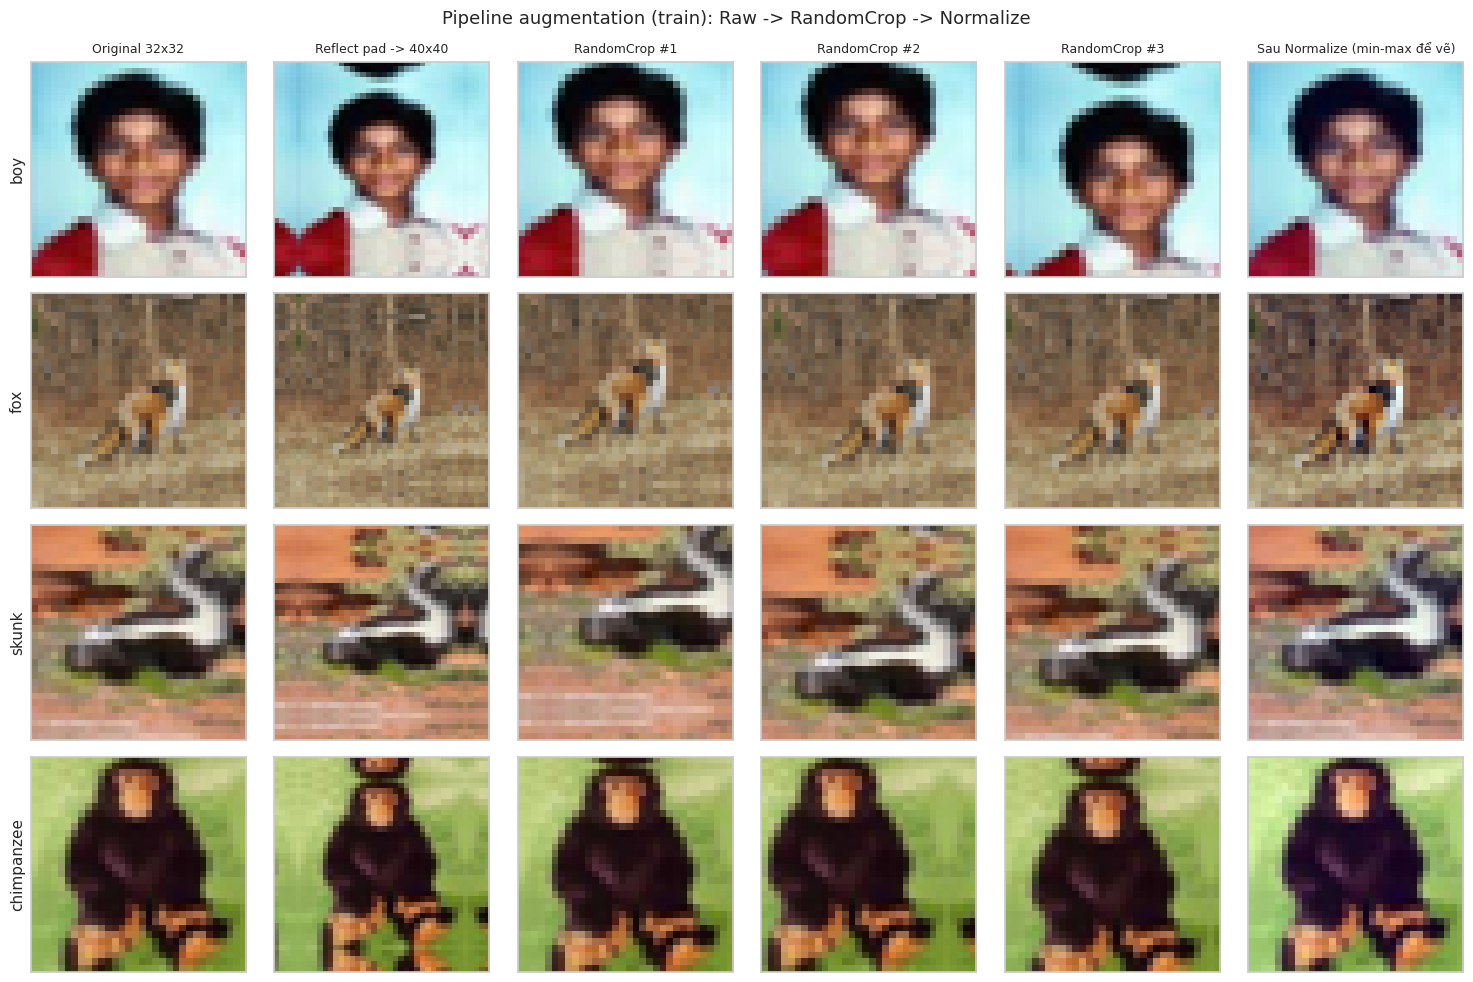

In [9]:
# Minh họa từng bước biến đổi: Original -> Reflect-pad 40x40 -> 3 lần RandomCrop khác nhau -> Normalized
ids = [3, 120, 777, 4096]
fig, axes = plt.subplots(len(ids), 6, figsize=(15, 10))
titles = ["Original 32x32", "Reflect pad -> 40x40", "RandomCrop #1", "RandomCrop #2", "RandomCrop #3", "Sau Normalize (min-max để vẽ)"]
for r, i in enumerate(ids):
    img = raw_train[i][0]                                       # PIL image
    padded = T.Pad(4, padding_mode="reflect")(img)
    axes[r, 0].imshow(img); axes[r, 1].imshow(padded)
    for c in range(3):
        axes[r, 2 + c].imshow(T.RandomCrop(32)(padded))         # mỗi lần cắt ở vị trí khác nhau
    t = eval_tf(img)                                            # tensor đã normalize
    axes[r, 5].imshow(((t - t.min()) / (t.max() - t.min())).permute(1, 2, 0).numpy())
    axes[r, 0].set_ylabel(CLASS_NAMES[raw_train.targets[i]], fontsize=11)
    for c in range(6):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0: axes[r, c].set_title(titles[c], fontsize=9)
plt.suptitle("Pipeline augmentation (train): Raw -> RandomCrop -> Normalize", fontsize=13)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/augmentation_demo.png", dpi=150); plt.show()

## 6. Mô hình ViT-Small

In [ ]:
def build_model(cfg, pretrained=None):
    use_pre = cfg["pretrained"] if pretrained is None else pretrained
    return timm.create_model(
        ARCH, pretrained=use_pre, num_classes=NUM_CLASSES,
        img_size=IMG_SIZE, patch_size=PATCH_SIZE, drop_path_rate=cfg["drop_path"])

def apply_freeze(model, mode):
    if mode == "none":                         # full: mọi tham số đều học
        for p in model.parameters(): p.requires_grad = True
        return model
    for p in model.parameters(): p.requires_grad = False        # mặc định khóa hết
    if mode == "all":                          # chỉ mở head
        for p in model.head.parameters(): p.requires_grad = True
    elif mode == "partial":                    # mở các block cuối + norm + head
        for blk in model.blocks[PARTIAL_FREEZE_BLOCKS:]:
            for p in blk.parameters(): p.requires_grad = True
        for p in model.norm.parameters(): p.requires_grad = True
        for p in model.head.parameters(): p.requires_grad = True
    else:
        raise ValueError(mode)
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def group_of(pname):
    parts = pname.split(".")
    return f"blocks.{int(parts[1]):02d}" if parts[0] == "blocks" else parts[0]

In [12]:
# (a) Kiểm tra kiến trúc + shape đầu vào/đầu ra
m = build_model(EXPERIMENTS["scratch"]).to(DEVICE).eval()
with torch.no_grad():
    out = m(torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
print("Input  : (2, 3, %d, %d)" % (IMG_SIZE, IMG_SIZE))
print("Số patch:", m.patch_embed.num_patches, "(+1 CLS token) | Embedding dim:", m.embed_dim, "| Depth:", len(m.blocks))
print("Output : ", tuple(out.shape), "-> (batch, 100 lớp)")
print("\npatch_embed:", m.patch_embed.proj)
print("pos_embed  :", tuple(m.pos_embed.shape), "(1, 1+64 token, 384)")
print("\n Transformer block:\n", m.blocks[0])
print("\nHead:", m.head)
del m

Input  : (2, 3, 32, 32)
Số patch: 64 (+1 CLS token) | Embedding dim: 384 | Depth: 12
Output :  (2, 100) -> (batch, 100 lớp)

patch_embed: Conv2d(3, 384, kernel_size=(4, 4), stride=(4, 4))
pos_embed  : (1, 65, 384) (1, 1+64 token, 384)

 Transformer block:
 Block(
  (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
  (attn): Attention(
    (qkv): Linear(in_features=384, out_features=1152, bias=True)
    (q_norm): Identity()
    (k_norm): Identity()
    (attn_drop): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (proj): Linear(in_features=384, out_features=384, bias=True)
    (proj_drop): Dropout(p=0.0, inplace=False)
  )
  (ls1): Identity()
  (drop_path1): Identity()
  (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
  (mlp): Mlp(
    (fc1): Linear(in_features=384, out_features=1536, bias=True)
    (act): GELU(approximate='none')
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (fc2): Linear(in_features=1536

In [13]:
# (b) Nạp thử bản pretrained: xem trọng số patch_embed / pos_embed đã được nội suy đúng kích thước chưa
mp = build_model(EXPERIMENTS["pre_full_ft"])
print("Pretrained patch_embed weight:", tuple(mp.patch_embed.proj.weight.shape), "(384 kênh, 3 RGB, 4x4)")
print("Pretrained pos_embed         :", tuple(mp.pos_embed.shape))
print("Head mới (khởi tạo ngẫu nhiên):", mp.head)
del mp

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Pretrained patch_embed weight: (384, 3, 4, 4) (384 kênh, 3 RGB, 4x4)
Pretrained pos_embed         : (1, 65, 384)
Head mới (khởi tạo ngẫu nhiên): Linear(in_features=384, out_features=100, bias=True)


In [14]:
# (c) Bảng so sánh: khối nào bị đóng băng ở mỗi thí nghiệm + số tham số trainable
rows, status = [], {}
for name in ORDER:
    cfg = EXPERIMENTS[name]
    m = apply_freeze(build_model(cfg, pretrained=False), cfg["freeze"])   # trạng thái đóng băng không phụ thuộc trọng số
    tot, tr = count_params(m)
    rows.append(dict(Experiment=cfg["title"], Total_params=tot, Trainable_params=tr, Trainable_pct=round(100 * tr / tot, 2), LR=cfg["lr"]))
    st = {}
    for pn, p in m.named_parameters():
        g_ = group_of(pn); st.setdefault(g_, [0, 0]); st[g_][0] += p.numel(); st[g_][1] += int(p.requires_grad) * p.numel()
    status[name] = {k: ("TRAIN" if v[1] == v[0] else "frozen") for k, v in st.items()}
    del m
param_df = pd.DataFrame(rows)
display(param_df)
display(pd.DataFrame(status).rename(columns={k: EXPERIMENTS[k]["title"] for k in ORDER}))
param_df.to_csv(f"{OUT_DIR}/params_table.csv", index=False)

,Experiment,Total_params,Trainable_params,Trainable_pct,LR
0,ViT-S From-Scratch,21376996,21376996,100.00,0.0003
1,Pretrained - Freeze Backbone,21376996,38500,0.18,0.0010
2,Pretrained - Partial Freeze,21376996,10686052,49.99,0.0002
3,Pretrained - Full Fine-tune,21376996,21376996,100.00,0.0001


,ViT-S From-Scratch,Pretrained - Freeze Backbone,Pretrained - Partial Freeze,Pretrained - Full Fine-tune
cls_token,TRAIN,frozen,frozen,TRAIN
pos_embed,TRAIN,frozen,frozen,TRAIN
patch_embed,TRAIN,frozen,frozen,TRAIN
blocks.00,TRAIN,frozen,frozen,TRAIN
blocks.01,TRAIN,frozen,frozen,TRAIN
blocks.02,TRAIN,frozen,frozen,TRAIN
blocks.03,TRAIN,frozen,frozen,TRAIN
blocks.04,TRAIN,frozen,frozen,TRAIN
blocks.05,TRAIN,frozen,frozen,TRAIN
blocks.06,TRAIN,frozen,TRAIN,TRAIN


## 7. Hàm huấn luyện / đánh giá

In [ ]:
# ---------- Lưu kết quả của các thí nghiệm ----------
RESULTS = {}   # name -> {"history": ..., "meta": ..., "test": ...}

def evaluate(model, loader):
    model.eval()                                  # tắt dropout / drop-path
    loss_sum, preds, labels, confs = 0.0, [], [], []
    with torch.no_grad():                         # không tính gradient -> nhanh, nhẹ bộ nhớ
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)                        # logits, shape (B, 100)
            loss_sum += F.cross_entropy(out, y, reduction="sum").item()
            conf, pred = F.softmax(out, dim=1).max(1)
            preds.append(pred.cpu()); labels.append(y.cpu()); confs.append(conf.cpu())
    preds, labels, confs = torch.cat(preds).numpy(), torch.cat(labels).numpy(), torch.cat(confs).numpy()
    return loss_sum / len(labels), 100 * (preds == labels).mean(), preds, labels, confs

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()                     # xóa gradient của batch trước
        out = model(x)                            # forward
        loss = criterion(out, y)                  # Cross-Entropy
        loss.backward()                           # backward: tính gradient
        optimizer.step()                          # cập nhật tham số (chỉ tham số trainable)
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return loss_sum / n, 100 * correct / n

def run_experiment(name):
    cfg = EXPERIMENTS[name]
    set_seed(SEED)
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()

    model = apply_freeze(build_model(cfg), cfg["freeze"]).to(DEVICE)    # tạo model + đóng băng
    total, trainable = count_params(model)
    print(f"=== {cfg['title']} ===")
    print(f"Tham số: total={total:,} | trainable={trainable:,} ({100*trainable/total:.2f}%) | LR={cfg['lr']} | epochs={EPOCHS}")

    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],   # chỉ đưa tham số trainable vào optimizer
                                  lr=cfg["lr"], weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)     # LR giảm dần theo cosine
    criterion = nn.CrossEntropyLoss()

    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best_val, best_ep, start = 0.0, 0, time.time()
    for ep in range(1, EPOCHS + 1):
        tl, ta = train_one_epoch(model, train_loader, optimizer, criterion)
        vl, va, _, _, _ = evaluate(model, val_loader)
        scheduler.step()
        for k, v in zip(hist, [tl, ta, vl, va]): hist[k].append(v)
        mark = ""
        if va > best_val:                                         # tốt nhất trên validation -> lưu checkpoint
            best_val, best_ep = va, ep
            torch.save(model.state_dict(), f"{OUT_DIR}/{name}_best.pt"); mark = " *best"
        print(f"Epoch {ep:02d}/{EPOCHS} | train loss {tl:.4f} acc {ta:5.2f}% | val loss {vl:.4f} acc {va:5.2f}%{mark}")

    elapsed = time.time() - start
    peak_mem = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else 0
    RESULTS[name] = dict(history=hist, meta=dict(
        title=cfg["title"], total_params=total, trainable_params=trainable, best_val_acc=best_val, best_epoch=best_ep,
        train_time_s=elapsed, sec_per_epoch=elapsed / EPOCHS, peak_mem_mb=peak_mem, lr=cfg["lr"], epochs=EPOCHS))
    print(f"-> best val acc {best_val:.2f}% @ epoch {best_ep} | {elapsed/60:.1f} phút | GPU mem đỉnh {peak_mem:.0f} MB")
    del model, optimizer; gc.collect(); torch.cuda.empty_cache()

def plot_curves(name):
    h, meta = RESULTS[name]["history"], RESULTS[name]["meta"]
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, h["train_loss"], label="Train"); ax[0].plot(ep, h["val_loss"], label="Validation")
    ax[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-Entropy"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="Train"); ax[1].plot(ep, h["val_acc"], label="Validation")
    ax[1].axvline(meta["best_epoch"], ls="--", c="gray", label=f"best epoch = {meta['best_epoch']}")
    ax[1].set(title="Accuracy (%)", xlabel="Epoch", ylabel="%"); ax[1].legend()
    plt.suptitle(meta["title"]); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves_{name}.png", dpi=150); plt.show()

In [ ]:
EVAL = {}   # name -> kết quả dự đoán trên test (dùng để vẽ confusion matrix, ảnh sai...)

def evaluate_test(name):
    model = build_model(EXPERIMENTS[name], pretrained=False).to(DEVICE)
    model.load_state_dict(torch.load(f"{OUT_DIR}/{name}_best.pt", map_location=DEVICE))
    loss, acc, preds, labels, confs = evaluate(model, test_loader)

    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)   # trung bình 100 lớp
    pp, rp, fp, sp = precision_recall_fscore_support(labels, preds, zero_division=0)                 # chỉ số từng lớp
    per_class = pd.DataFrame({"class": CLASS_NAMES, "accuracy_%": 100 * rp, "precision": pp, "recall": rp, "f1": fp, "support": sp})
    EVAL[name] = dict(preds=preds, labels=labels, confs=confs, cm=confusion_matrix(labels, preds), per_class=per_class)
    RESULTS[name]["test"] = dict(acc=acc, loss=loss, precision_macro=p, recall_macro=r, f1_macro=f1, per_class=per_class.to_dict("list"))
    del model; gc.collect(); torch.cuda.empty_cache()

def denorm(t):
    m, s = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

def show_report(name):
    if name not in EVAL: evaluate_test(name)
    E, t, title = EVAL[name], RESULTS[name]["test"], EXPERIMENTS[name]["title"]

    print(f"===== {title}: KẾT QUẢ TRÊN TEST =====")
    display(pd.DataFrame([dict(Accuracy=f"{t['acc']:.2f}%", Test_loss=round(t["loss"], 4), Precision=round(t["precision_macro"], 4),
                               Recall=round(t["recall_macro"], 4), F1=round(t["f1_macro"], 4))]))
    print("\n--- Accuracy / Precision / Recall / F1 của 100 lớp ---")
    display(E["per_class"].round(3))

    plt.figure(figsize=(10, 8))                                  # confusion matrix 20 lớp đầu (giống report)
    sns.heatmap(E["cm"][:20, :20], annot=True, fmt="d", cmap="viridis", xticklabels=CLASS_NAMES[:20], yticklabels=CLASS_NAMES[:20])
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.xticks(rotation=45, ha="right"); plt.title(f"Confusion Matrix (20 lớp đầu) - {title}")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cm20_{name}.png", dpi=150); plt.show()

    cm = E["cm"].copy(); np.fill_diagonal(cm, 0)                 # bỏ đường chéo -> chỉ còn các lần nhầm
    top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:10], cm.shape))[0]
    print("--- 10 cặp lớp bị nhầm nhiều nhất ---")
    display(pd.DataFrame([dict(True_class=CLASS_NAMES[i], Predicted_as=CLASS_NAMES[j], Count=int(cm[i, j])) for i, j in top]))

    wrong = np.where(E["preds"] != E["labels"])[0]               # 12 ảnh dự đoán sai (chọn ngẫu nhiên cố định seed)
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    for ax, i in zip(axes.ravel(), np.random.RandomState(SEED).choice(wrong, 12, replace=False)):
        ax.imshow(denorm(test_set[i][0])); ax.axis("off")
        ax.set_title(f"True: {CLASS_NAMES[E['labels'][i]]}\nPred: {CLASS_NAMES[E['preds'][i]]} ({100*E['confs'][i]:.0f}%)", fontsize=9)
    plt.suptitle(f"Ảnh dự đoán sai - {title}"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/misclassified_{name}.png", dpi=150); plt.show()

## 8.1 Thí nghiệm 1: ViT-S From-Scratch

=== ViT-S From-Scratch ===
Tham số: total=21,376,996 | trainable=21,376,996 (100.00%) | LR=0.0003 | epochs=20
Epoch 01/20 | train loss 3.9657 acc  8.90% | val loss 3.6818 acc 12.51% *best
Epoch 02/20 | train loss 3.5026 acc 16.14% | val loss 3.2995 acc 18.97% *best
Epoch 03/20 | train loss 3.2070 acc 20.96% | val loss 3.0608 acc 23.35% *best
Epoch 04/20 | train loss 3.0040 acc 24.89% | val loss 2.8857 acc 27.24% *best
Epoch 05/20 | train loss 2.8393 acc 27.62% | val loss 2.7735 acc 28.80% *best
Epoch 06/20 | train loss 2.6919 acc 30.86% | val loss 2.6559 acc 31.65% *best
Epoch 07/20 | train loss 2.5633 acc 33.49% | val loss 2.5780 acc 33.10% *best
Epoch 08/20 | train loss 2.4466 acc 35.89% | val loss 2.4648 acc 36.37% *best
Epoch 09/20 | train loss 2.3168 acc 38.61% | val loss 2.4256 acc 36.73% *best
Epoch 10/20 | train loss 2.1980 acc 41.26% | val loss 2.3599 acc 38.39% *best
Epoch 11/20 | train loss 2.0714 acc 43.99% | val loss 2.3043 acc 39.83% *best
Epoch 12/20 | train loss 1.9402 

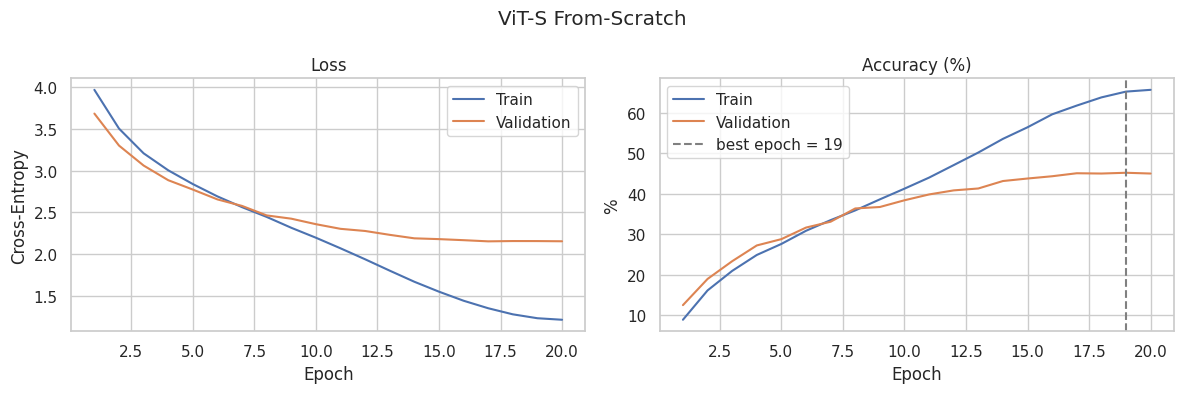

In [17]:
# Huấn luyện + vẽ đường cong loss / accuracy / learning rate
run_experiment("scratch")
plot_curves("scratch")

### 8.1b Đánh giá trên tập Test – ViT-S From-Scratch

===== ViT-S From-Scratch: KẾT QUẢ TRÊN TEST =====


,Accuracy,Test_loss,Precision,Recall,F1
0,46.46%,2.1005,0.4602,0.4646,0.4604



--- Accuracy / Precision / Recall / F1 của 100 lớp ---


,class,accuracy_%,precision,recall,f1,support
0,apple,75.0,0.694,0.75,0.721,100
1,aquarium_fish,64.0,0.547,0.64,0.590,100
2,baby,47.0,0.423,0.47,0.445,100
3,bear,25.0,0.309,0.25,0.276,100
4,beaver,32.0,0.308,0.32,0.314,100
5,bed,35.0,0.385,0.35,0.366,100
6,bee,55.0,0.491,0.55,0.519,100
7,beetle,60.0,0.541,0.60,0.569,100
8,bicycle,48.0,0.500,0.48,0.490,100
9,bottle,45.0,0.474,0.45,0.462,100


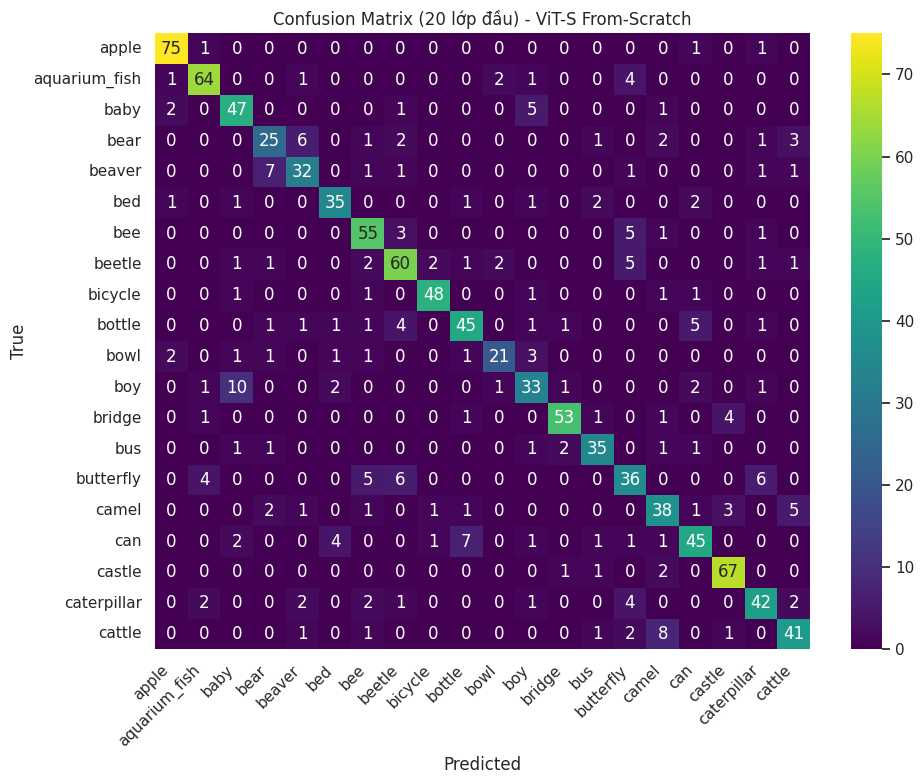

--- 10 cặp lớp bị nhầm nhiều nhất ---


,True_class,Predicted_as,Count
0,maple_tree,oak_tree,29
1,pine_tree,oak_tree,21
2,bus,pickup_truck,17
3,whale,dolphin,16
4,baby,girl,15
5,willow_tree,oak_tree,15
6,boy,girl,15
7,tulip,rose,14
8,woman,girl,14
9,plate,clock,13


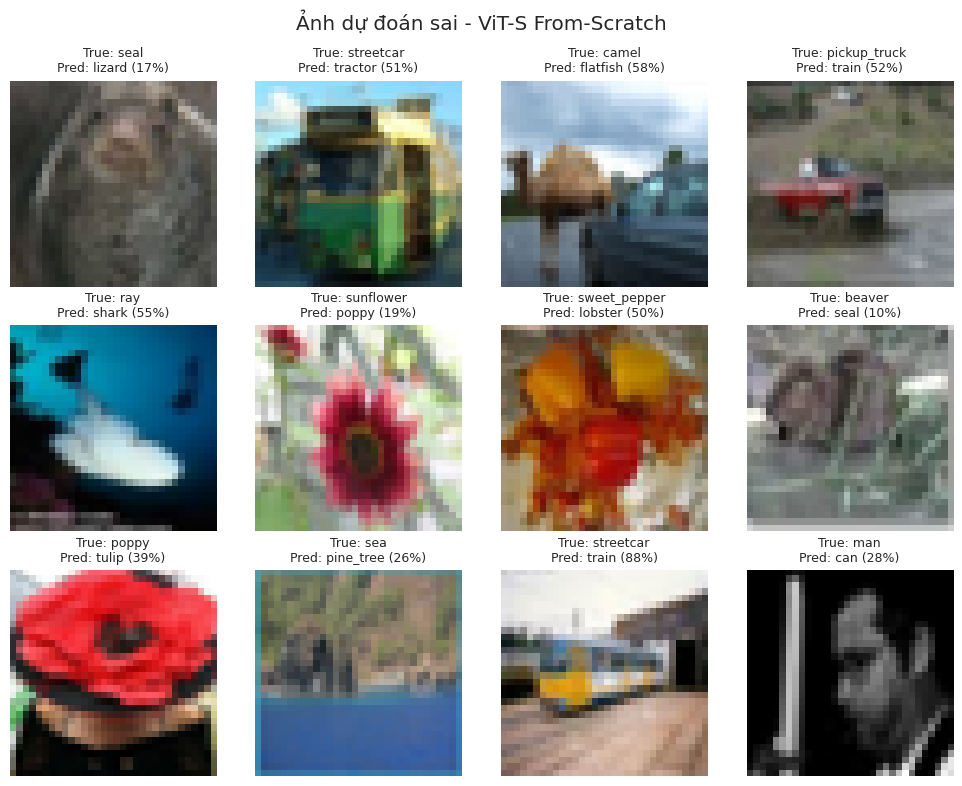

In [18]:
# Nạp checkpoint tốt nhất (theo val), đánh giá test: metric, bảng 100 lớp, confusion matrix, cặp bị nhầm, ảnh dự đoán sai
show_report("scratch")

## 8.2 Thí nghiệm 2: Pretrained – Freeze toàn bộ backbone (chỉ train head)

=== Pretrained - Freeze Backbone ===
Tham số: total=21,376,996 | trainable=38,500 (0.18%) | LR=0.001 | epochs=20
Epoch 01/20 | train loss 2.1725 acc 46.21% | val loss 1.4946 acc 59.94% *best
Epoch 02/20 | train loss 1.5437 acc 57.83% | val loss 1.3802 acc 62.37% *best
Epoch 03/20 | train loss 1.4361 acc 60.41% | val loss 1.3419 acc 63.06% *best
Epoch 04/20 | train loss 1.3838 acc 61.73% | val loss 1.3271 acc 63.97% *best
Epoch 05/20 | train loss 1.3363 acc 62.86% | val loss 1.3193 acc 63.82%
Epoch 06/20 | train loss 1.3068 acc 63.60% | val loss 1.3033 acc 64.02% *best
Epoch 07/20 | train loss 1.2830 acc 64.05% | val loss 1.3069 acc 64.31% *best
Epoch 08/20 | train loss 1.2681 acc 64.63% | val loss 1.2990 acc 64.50% *best
Epoch 09/20 | train loss 1.2379 acc 65.18% | val loss 1.3021 acc 64.51% *best
Epoch 10/20 | train loss 1.2274 acc 65.35% | val loss 1.2812 acc 64.97% *best
Epoch 11/20 | train loss 1.2095 acc 65.92% | val loss 1.2767 acc 64.95%
Epoch 12/20 | train loss 1.2012 acc 66.16

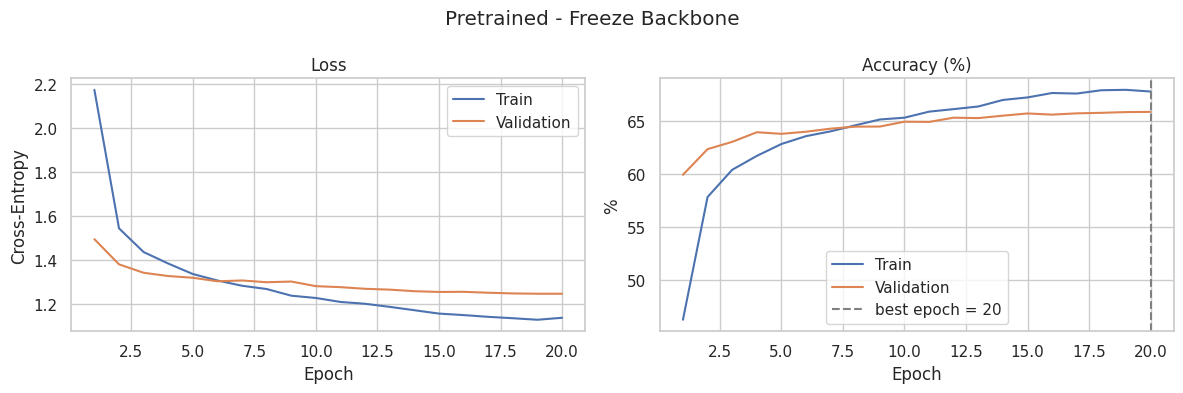

In [19]:
# Huấn luyện + vẽ đường cong loss / accuracy / learning rate
run_experiment("pre_freeze_all")
plot_curves("pre_freeze_all")

### 8.2b Đánh giá trên tập Test – Pretrained – Freeze toàn bộ backbone (chỉ train head)

===== Pretrained - Freeze Backbone: KẾT QUẢ TRÊN TEST =====


,Accuracy,Test_loss,Precision,Recall,F1
0,65.55%,1.2358,0.6572,0.6555,0.6546



--- Accuracy / Precision / Recall / F1 của 100 lớp ---


,class,accuracy_%,precision,recall,f1,support
0,apple,90.0,0.918,0.90,0.909,100
1,aquarium_fish,77.0,0.733,0.77,0.751,100
2,baby,56.0,0.571,0.56,0.566,100
3,bear,42.0,0.532,0.42,0.469,100
4,beaver,47.0,0.470,0.47,0.470,100
5,bed,65.0,0.607,0.65,0.628,100
6,bee,71.0,0.612,0.71,0.657,100
7,beetle,70.0,0.714,0.70,0.707,100
8,bicycle,78.0,0.918,0.78,0.843,100
9,bottle,66.0,0.892,0.66,0.759,100


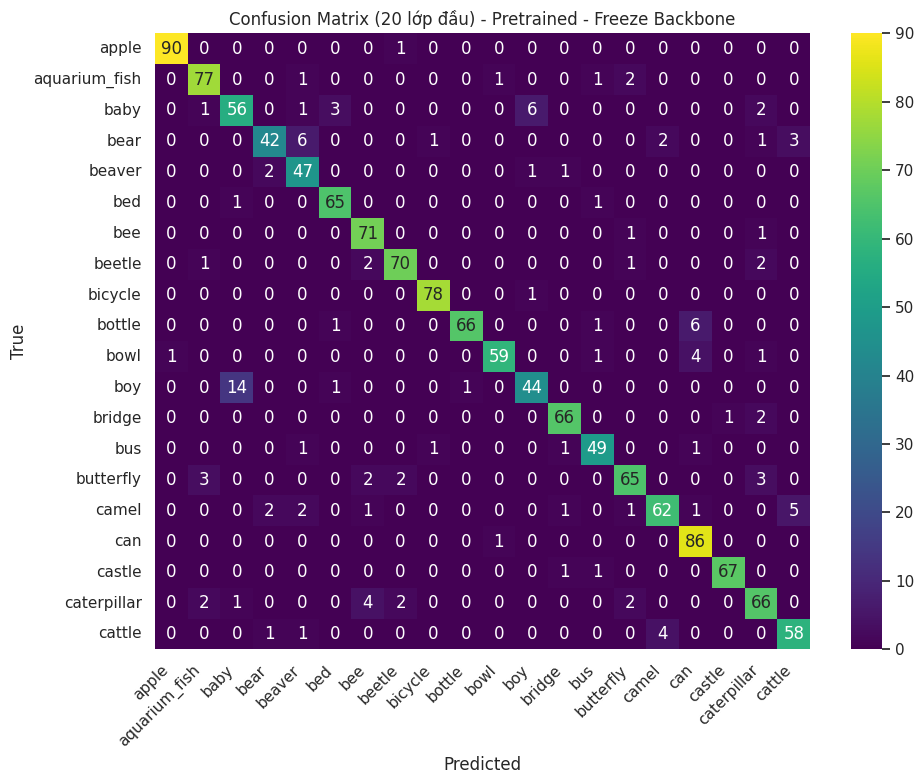

--- 10 cặp lớp bị nhầm nhiều nhất ---


,True_class,Predicted_as,Count
0,maple_tree,oak_tree,24
1,pine_tree,oak_tree,22
2,bus,streetcar,18
3,girl,boy,16
4,crab,lobster,15
5,plate,bowl,15
6,oak_tree,maple_tree,14
7,boy,baby,14
8,seal,otter,14
9,otter,seal,13


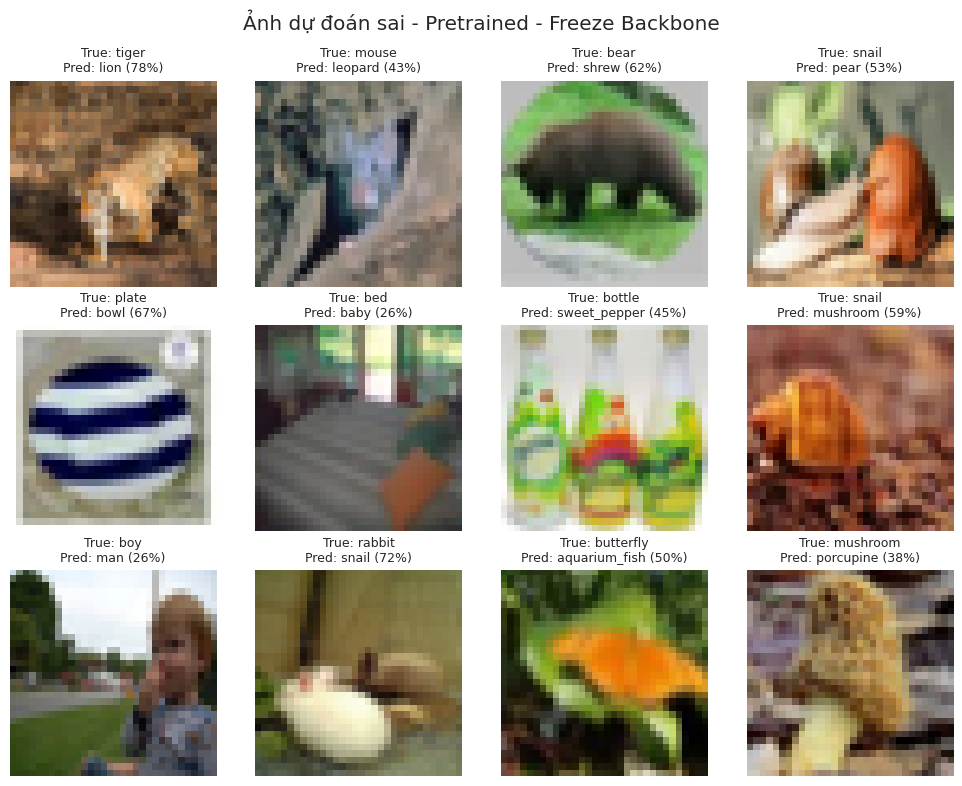

In [20]:
# Nạp checkpoint tốt nhất (theo val), đánh giá test: metric, bảng 100 lớp, confusion matrix, cặp bị nhầm, ảnh dự đoán sai
show_report("pre_freeze_all")

## 8.3 Thí nghiệm 3: Pretrained – Partial freeze (khóa 6 block đầu)

=== Pretrained - Partial Freeze ===
Tham số: total=21,376,996 | trainable=10,686,052 (49.99%) | LR=0.0002 | epochs=20
Epoch 01/20 | train loss 1.3810 acc 63.61% | val loss 0.8329 acc 76.14% *best
Epoch 02/20 | train loss 0.6722 acc 80.14% | val loss 0.7173 acc 79.23% *best
Epoch 03/20 | train loss 0.4966 acc 84.85% | val loss 0.7492 acc 78.93%
Epoch 04/20 | train loss 0.3819 acc 88.10% | val loss 0.7408 acc 79.26% *best
Epoch 05/20 | train loss 0.2852 acc 91.03% | val loss 0.7215 acc 80.27% *best
Epoch 06/20 | train loss 0.2259 acc 92.90% | val loss 0.7779 acc 79.53%
Epoch 07/20 | train loss 0.1735 acc 94.44% | val loss 0.7706 acc 80.34% *best
Epoch 08/20 | train loss 0.1384 acc 95.49% | val loss 0.7760 acc 80.42% *best
Epoch 09/20 | train loss 0.1128 acc 96.45% | val loss 0.7998 acc 80.73% *best
Epoch 10/20 | train loss 0.0821 acc 97.45% | val loss 0.7984 acc 81.11% *best
Epoch 11/20 | train loss 0.0662 acc 97.98% | val loss 0.8109 acc 81.00%
Epoch 12/20 | train loss 0.0504 acc 98.41%

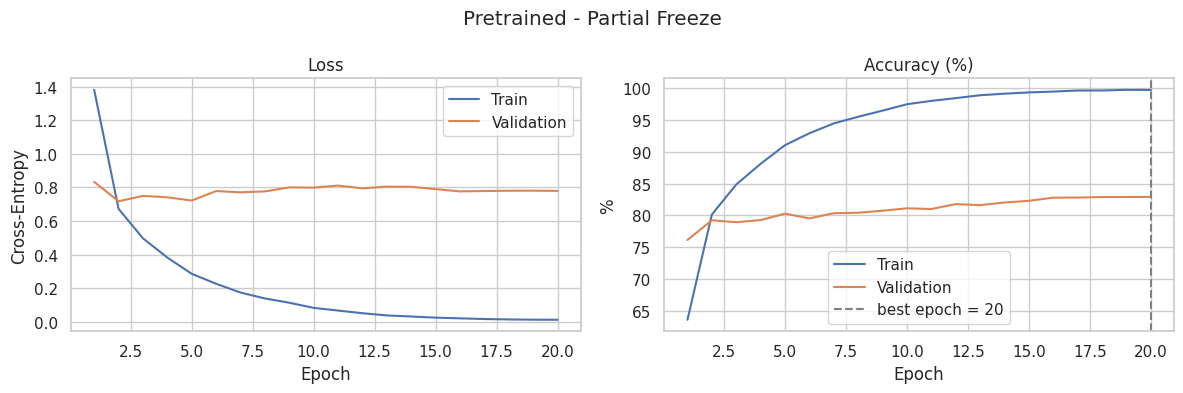

In [21]:
# Huấn luyện + vẽ đường cong loss / accuracy / learning rate
run_experiment("pre_freeze_partial")
plot_curves("pre_freeze_partial")

### 8.3b Đánh giá trên tập Test – Pretrained – Partial freeze (khóa 6 block đầu)

===== Pretrained - Partial Freeze: KẾT QUẢ TRÊN TEST =====


,Accuracy,Test_loss,Precision,Recall,F1
0,82.70%,0.7846,0.829,0.827,0.8271



--- Accuracy / Precision / Recall / F1 của 100 lớp ---


,class,accuracy_%,precision,recall,f1,support
0,apple,93.0,0.959,0.93,0.944,100
1,aquarium_fish,92.0,0.911,0.92,0.915,100
2,baby,72.0,0.667,0.72,0.692,100
3,bear,69.0,0.793,0.69,0.738,100
4,beaver,77.0,0.713,0.77,0.740,100
5,bed,88.0,0.889,0.88,0.884,100
6,bee,88.0,0.898,0.88,0.889,100
7,beetle,88.0,0.830,0.88,0.854,100
8,bicycle,91.0,0.883,0.91,0.897,100
9,bottle,83.0,0.922,0.83,0.874,100


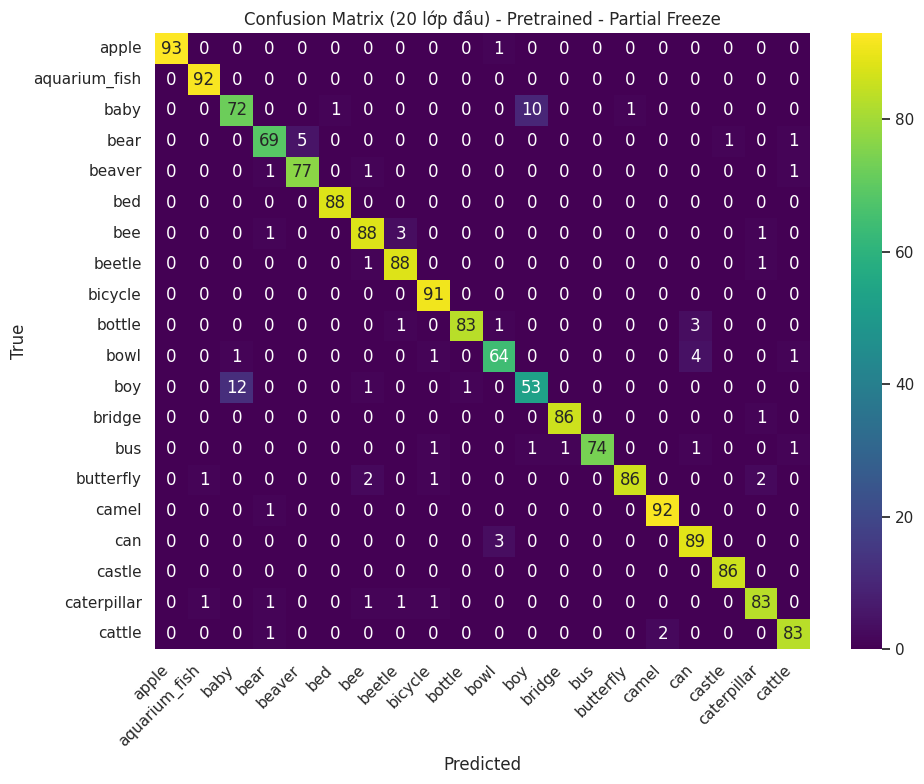

--- 10 cặp lớp bị nhầm nhiều nhất ---


,True_class,Predicted_as,Count
0,oak_tree,maple_tree,22
1,maple_tree,oak_tree,15
2,seal,otter,14
3,woman,man,14
4,bus,streetcar,13
5,crab,lobster,13
6,dolphin,shark,12
7,pine_tree,oak_tree,12
8,girl,baby,12
9,shrew,mouse,12


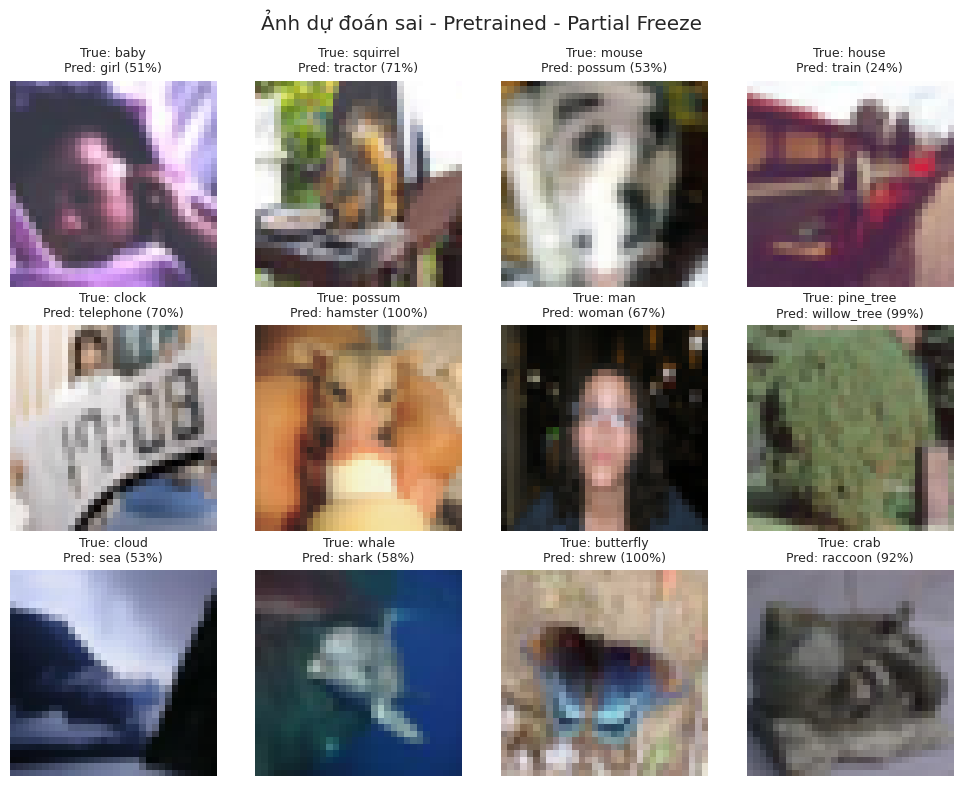

In [22]:
# Nạp checkpoint tốt nhất (theo val), đánh giá test: metric, bảng 100 lớp, confusion matrix, cặp bị nhầm, ảnh dự đoán sai
show_report("pre_freeze_partial")

## 8.4 Thí nghiệm 4: Pretrained – Full fine-tune

=== Pretrained - Full Fine-tune ===
Tham số: total=21,376,996 | trainable=21,376,996 (100.00%) | LR=0.0001 | epochs=20
Epoch 01/20 | train loss 1.3963 acc 65.48% | val loss 0.5520 acc 83.87% *best
Epoch 02/20 | train loss 0.4593 acc 86.39% | val loss 0.4848 acc 85.73% *best
Epoch 03/20 | train loss 0.3165 acc 90.26% | val loss 0.4921 acc 85.47%
Epoch 04/20 | train loss 0.2263 acc 92.93% | val loss 0.4812 acc 86.57% *best
Epoch 05/20 | train loss 0.1758 acc 94.43% | val loss 0.4848 acc 86.47%
Epoch 06/20 | train loss 0.1323 acc 95.80% | val loss 0.4962 acc 86.55%
Epoch 07/20 | train loss 0.1005 acc 96.79% | val loss 0.5140 acc 86.37%
Epoch 08/20 | train loss 0.0743 acc 97.75% | val loss 0.5382 acc 86.52%
Epoch 09/20 | train loss 0.0606 acc 98.18% | val loss 0.5252 acc 86.71% *best
Epoch 10/20 | train loss 0.0472 acc 98.59% | val loss 0.5299 acc 86.87% *best
Epoch 11/20 | train loss 0.0384 acc 98.82% | val loss 0.5399 acc 87.37% *best
Epoch 12/20 | train loss 0.0247 acc 99.35% | val loss

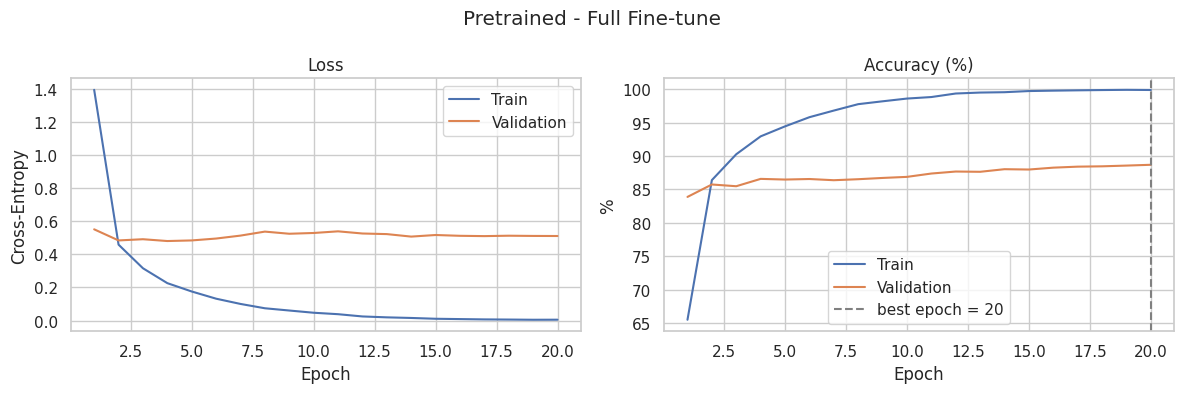

In [23]:
# Huấn luyện + vẽ đường cong loss / accuracy / learning rate
run_experiment("pre_full_ft")
plot_curves("pre_full_ft")

### 8.4b Đánh giá trên tập Test – Pretrained – Full fine-tune

===== Pretrained - Full Fine-tune: KẾT QUẢ TRÊN TEST =====


,Accuracy,Test_loss,Precision,Recall,F1
0,88.32%,0.511,0.8853,0.8832,0.8834



--- Accuracy / Precision / Recall / F1 của 100 lớp ---


,class,accuracy_%,precision,recall,f1,support
0,apple,95.0,0.941,0.95,0.945,100
1,aquarium_fish,91.0,0.910,0.91,0.910,100
2,baby,79.0,0.798,0.79,0.794,100
3,bear,80.0,0.870,0.80,0.833,100
4,beaver,80.0,0.808,0.80,0.804,100
5,bed,96.0,0.881,0.96,0.919,100
6,bee,94.0,0.969,0.94,0.954,100
7,beetle,94.0,0.870,0.94,0.904,100
8,bicycle,90.0,0.947,0.90,0.923,100
9,bottle,96.0,0.923,0.96,0.941,100


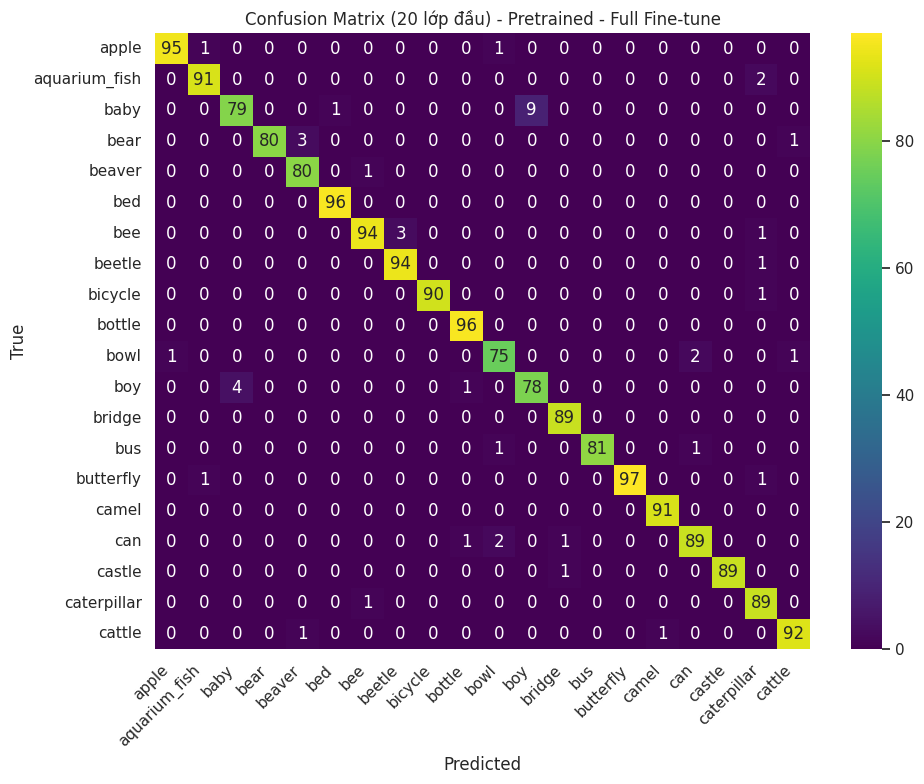

--- 10 cặp lớp bị nhầm nhiều nhất ---


,True_class,Predicted_as,Count
0,oak_tree,maple_tree,26
1,maple_tree,oak_tree,18
2,girl,baby,12
3,girl,woman,12
4,pine_tree,oak_tree,12
5,otter,seal,12
6,shrew,mouse,9
7,bus,streetcar,9
8,snake,worm,9
9,woman,man,9


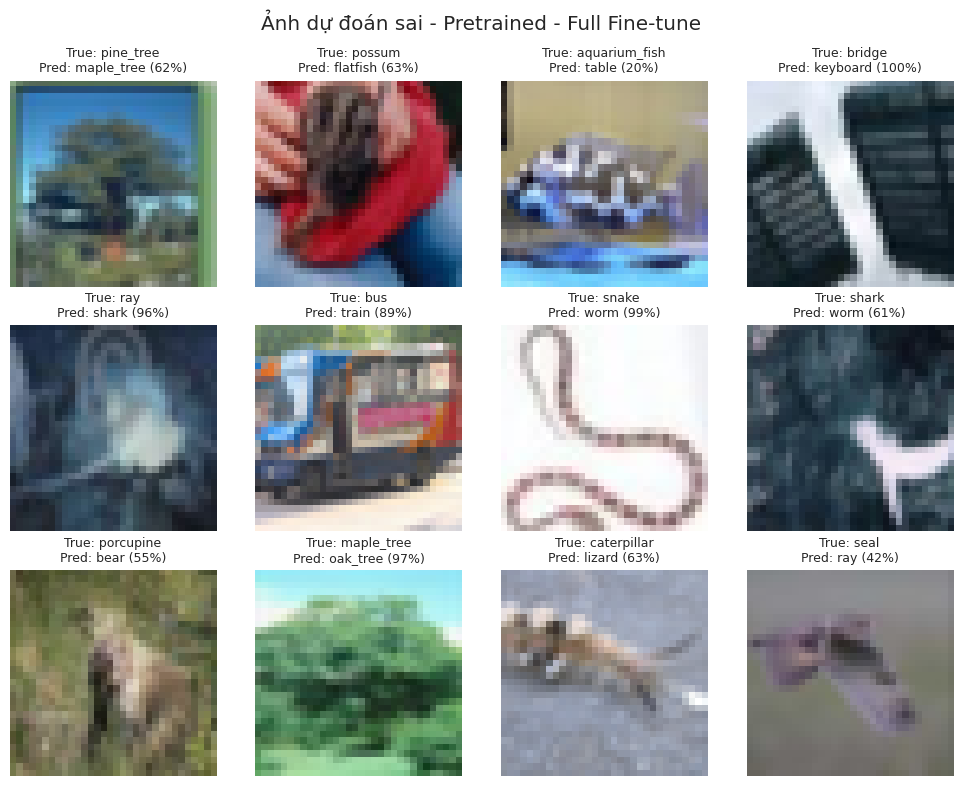

In [24]:
# Nạp checkpoint tốt nhất (theo val), đánh giá test: metric, bảng 100 lớp, confusion matrix, cặp bị nhầm, ảnh dự đoán sai
show_report("pre_full_ft")

## 9. So sánh 4 chế độ huấn luyện (bảng + biểu đồ)

In [ ]:
for n in ORDER:
    assert n in RESULTS and "test" in RESULTS[n], f"Chưa chạy đủ thí nghiệm '{n}' (cell 8.x và 8.xb)"

rows = []
for n in ORDER:
    R = RESULTS[n]; m, t, h = R["meta"], R["test"], R["history"]
    rows.append({
        "Experiment": m["title"],
        "Trainable params": m["trainable_params"],
        "Trainable %": round(100 * m["trainable_params"] / m["total_params"], 2),
        "Epochs": m["epochs"], "LR": m["lr"],
        "Best epoch": m["best_epoch"],
        "Final train loss": round(h["train_loss"][-1], 4),
        "Test loss": round(t["loss"], 4),
        "Final train acc %": round(h["train_acc"][-1], 2),
        "Best val acc %": round(m["best_val_acc"], 2),
        "Test acc %": round(t["acc"], 2),
        "Test macro-F1": round(t["f1_macro"], 4),
        "Train-Test gap (pp)": round(h["train_acc"][-1] - t["acc"], 2),
        "Train time (min)": round(m["train_time_s"] / 60, 1),
        "Sec/epoch": round(m["sec_per_epoch"], 1),
        "Peak GPU mem (MB)": round(m["peak_mem_mb"]),
    })
cmp_df = pd.DataFrame(rows).set_index("Experiment")
cmp_df.to_csv(f"{OUT_DIR}/comparison_table.csv")
display(cmp_df.T)    # chuyển vị cho dễ đọc 

Experiment,ViT-S From-Scratch,Pretrained - Freeze Backbone,Pretrained - Partial Freeze,Pretrained - Full Fine-tune
Trainable params,2.137700e+07,38500.0000,1.068605e+07,2.137700e+07
Trainable %,1.000000e+02,0.1800,4.999000e+01,1.000000e+02
Epochs,2.000000e+01,20.0000,2.000000e+01,2.000000e+01
LR,3.000000e-04,0.0010,2.000000e-04,1.000000e-04
Best epoch,1.900000e+01,20.0000,2.000000e+01,2.000000e+01
Final train loss,1.217600e+00,1.1377,1.140000e-02,5.100000e-03
Test loss,2.100500e+00,1.2358,7.846000e-01,5.110000e-01
Final train acc %,6.565000e+01,67.8300,9.970000e+01,9.987000e+01
Best val acc %,4.518000e+01,65.9000,8.290000e+01,8.868000e+01
Test acc %,4.646000e+01,65.5500,8.270000e+01,8.832000e+01


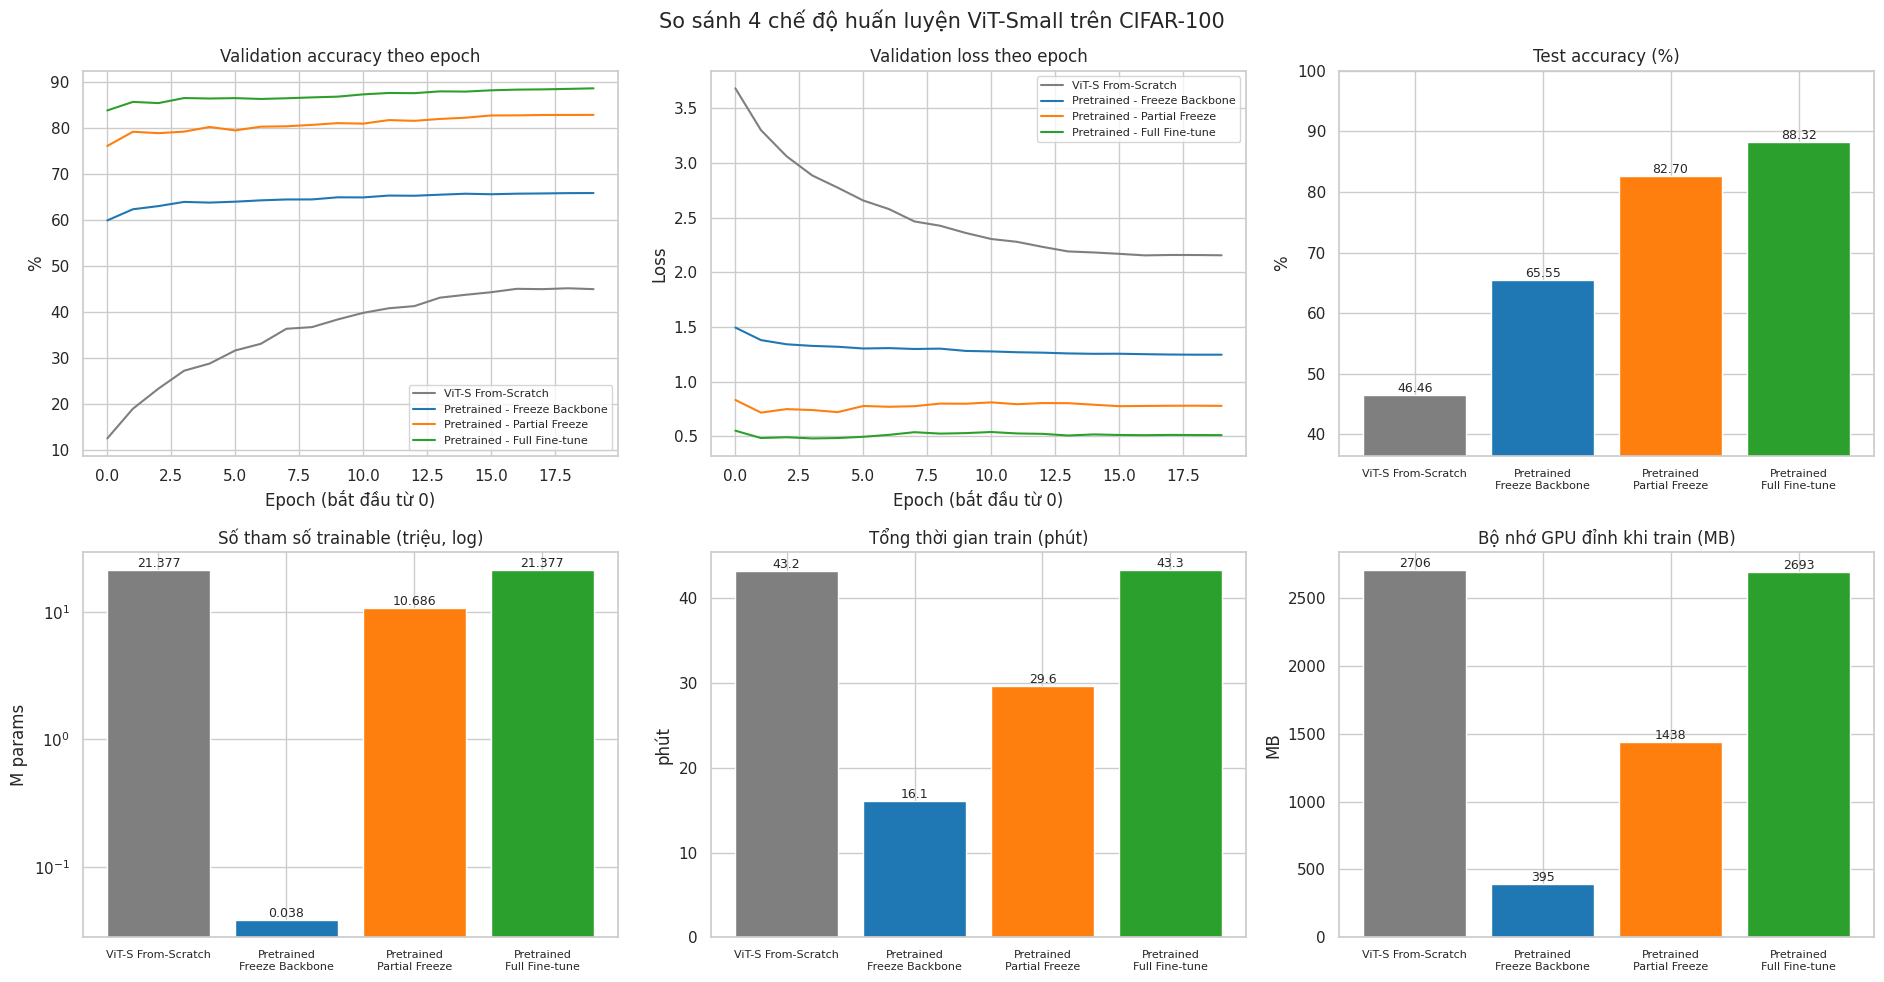

In [26]:
# Biểu đồ so sánh tổng hợp (2x3)
labels = [EXPERIMENTS[n]["title"].replace(" - ", "\n") for n in ORDER]
colors = ["tab:gray", "tab:blue", "tab:orange", "tab:green"]
fig, ax = plt.subplots(2, 3, figsize=(19, 10))

for n, c in zip(ORDER, colors):                                 # (0,0) Val acc theo epoch
    ax[0, 0].plot(RESULTS[n]["history"]["val_acc"], label=EXPERIMENTS[n]["title"], c=c)
ax[0, 0].set(title="Validation accuracy theo epoch", xlabel="Epoch (bắt đầu từ 0)", ylabel="%"); ax[0, 0].legend(fontsize=8)

for n, c in zip(ORDER, colors):                                 # (0,1) Val loss theo epoch
    ax[0, 1].plot(RESULTS[n]["history"]["val_loss"], label=EXPERIMENTS[n]["title"], c=c)
ax[0, 1].set(title="Validation loss theo epoch", xlabel="Epoch (bắt đầu từ 0)", ylabel="Loss"); ax[0, 1].legend(fontsize=8)

def bar(a, vals, title, ylabel, fmt="%.2f", log=False):
    b = a.bar(labels, vals, color=colors); a.set_title(title); a.set_ylabel(ylabel)
    if log: a.set_yscale("log")
    a.bar_label(b, labels=[fmt % v for v in vals], fontsize=9); a.tick_params(axis="x", labelsize=8)

bar(ax[0, 2], cmp_df["Test acc %"].values, "Test accuracy (%)", "%")
ax[0, 2].set_ylim(min(cmp_df["Test acc %"]) - 10, 100)
bar(ax[1, 0], cmp_df["Trainable params"].values / 1e6, "Số tham số trainable (triệu, log)", "M params", "%.3f", log=True)
bar(ax[1, 1], cmp_df["Train time (min)"].values, "Tổng thời gian train (phút)", "phút", "%.1f")
bar(ax[1, 2], cmp_df["Peak GPU mem (MB)"].values, "Bộ nhớ GPU đỉnh khi train (MB)", "MB", "%.0f")
plt.suptitle("So sánh 4 chế độ huấn luyện ViT-Small trên CIFAR-100", fontsize=15)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/compare_overview.png", dpi=150); plt.show()

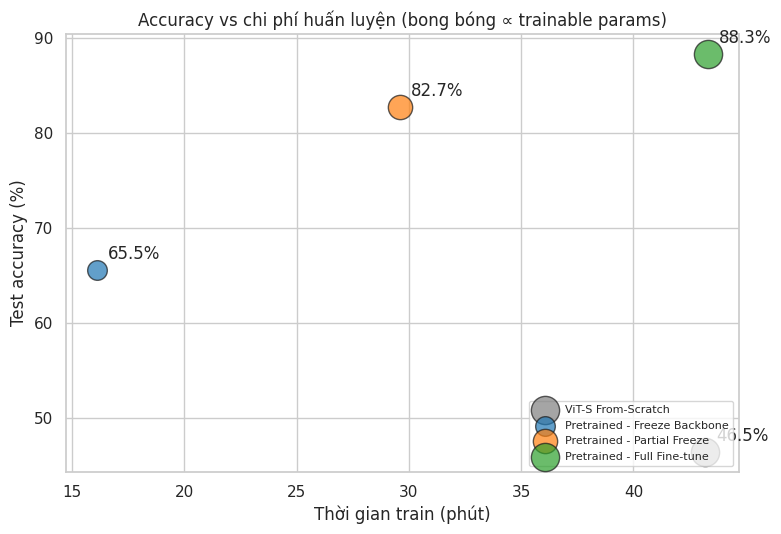

In [27]:
# Đánh đổi hiệu quả: Accuracy vs thời gian (kích thước bong bóng = số tham số trainable)
plt.figure(figsize=(8, 5.5))
for n, c in zip(ORDER, colors):
    m, t = RESULTS[n]["meta"], RESULTS[n]["test"]
    plt.scatter(m["train_time_s"] / 60, t["acc"], s=200 + m["trainable_params"] / 1e5, color=c, alpha=0.7, edgecolor="k", label=EXPERIMENTS[n]["title"])
    plt.annotate(f"{t['acc']:.1f}%", (m["train_time_s"] / 60, t["acc"]), textcoords="offset points", xytext=(8, 8))
plt.xlabel("Thời gian train (phút)"); plt.ylabel("Test accuracy (%)"); plt.legend(fontsize=8, loc="lower right")
plt.title("Accuracy vs chi phí huấn luyện (bong bóng ∝ trainable params)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/compare_tradeoff.png", dpi=150); plt.show()

Accuracy theo lớp của cả 4 chế độ (test):


,ViT-S From-Scratch,Pretrained - Freeze Backbone,Pretrained - Partial Freeze,Pretrained - Full Fine-tune,Gain: FullFT - Scratch
apple,75.0,90.0,93.0,95.0,20.0
aquarium_fish,64.0,77.0,92.0,91.0,27.0
baby,47.0,56.0,72.0,79.0,32.0
bear,25.0,42.0,69.0,80.0,55.0
beaver,32.0,47.0,77.0,80.0,48.0
bed,35.0,65.0,88.0,96.0,61.0
bee,55.0,71.0,88.0,94.0,39.0
beetle,60.0,70.0,88.0,94.0,34.0
bicycle,48.0,78.0,91.0,90.0,42.0
bottle,45.0,66.0,83.0,96.0,51.0


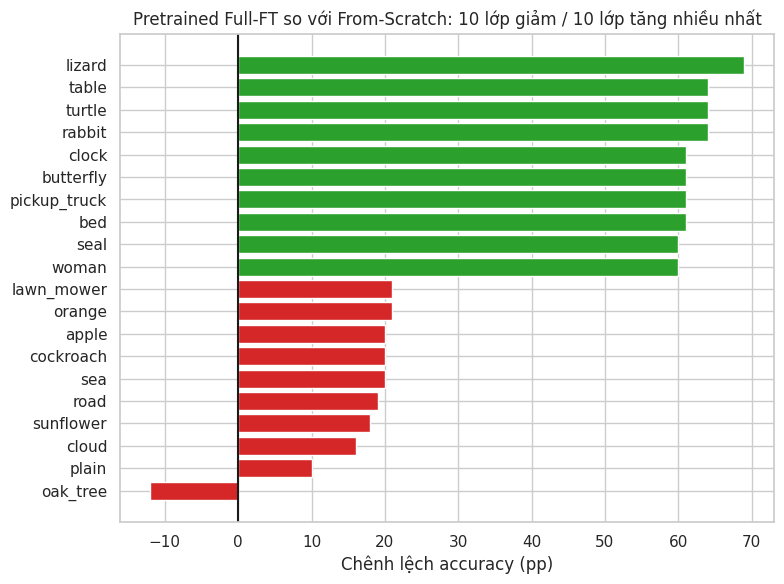

In [28]:
# So sánh accuracy theo từng lớp giữa 4 chế độ + lớp được lợi nhiều nhất từ pretrain
pc = pd.DataFrame({EXPERIMENTS[n]["title"]: RESULTS[n]["test"]["per_class"]["accuracy_%"] for n in ORDER}, index=CLASS_NAMES)
pc["Gain: FullFT - Scratch"] = pc[EXPERIMENTS["pre_full_ft"]["title"]] - pc[EXPERIMENTS["scratch"]["title"]]
print("Accuracy theo lớp của cả 4 chế độ (test):")
display(pc.round(1))

g_ = pc["Gain: FullFT - Scratch"].sort_values()
sel = pd.concat([g_.head(10), g_.tail(10)])
plt.figure(figsize=(8, 6)); plt.barh(sel.index, sel.values, color=["tab:red"] * 10 + ["tab:green"] * 10)
plt.axvline(0, c="k"); plt.xlabel("Chênh lệch accuracy (pp)"); plt.title("Pretrained Full-FT so với From-Scratch: 10 lớp giảm / 10 lớp tăng nhiều nhất")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/compare_perclass_gain.png", dpi=150); plt.show()

## 10. Đóng gói kết quả để nộp (code + hình + bảng)

In [29]:
# Nén toàn bộ hình/bảng/json (bỏ file .pt nặng) để tải về đưa vào report & GitHub
import shutil, glob
pack = "/content/a1_report_assets"
os.makedirs(pack, exist_ok=True)
for f in glob.glob(f"{OUT_DIR}/*.png") + glob.glob(f"{OUT_DIR}/*.csv") + glob.glob(f"{OUT_DIR}/*.json"):
    shutil.copy(f, pack)
shutil.make_archive("/content/a1_report_assets", "zip", pack)
print("Đã tạo /content/a1_report_assets.zip gồm:", len(os.listdir(pack)), "file")

try:
    from google.colab import files
    files.download("/content/a1_report_assets.zip")      # tải về máy
except Exception as e:
    print("Không ở Colab hoặc không tải được:", e)

Đã tạo /content/a1_report_assets.zip gồm: 20 file


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>